In [11]:
%load_ext autoreload
%autoreload 2

# standard imports
import os
import numpy as np
from sklearn.linear_model import Ridge
import torch
import re
from sklearn.model_selection import StratifiedKFold
import scipy
from tqdm.notebook import tqdm
import pandas as pd
import warnings
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# custom imports

from compcats.models import resnet50_openaiclip
from compcats.datasets.fmri import murty185
from compcats.utils import model_utils, misc_utils, responsecomparison_utils
from compcats.encoder import encode

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
from matplotlib.font_manager import FontProperties
rcParams.update({
    'figure.autolayout': False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    })
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
MODELS_DIR = '/Users/adipani3/projects/catsel/comparing-category-selectivity/preprint/models'
os.makedirs(MODELS_DIR, exist_ok=True)
MURTY185_DIR = '/Users/adipani3/datasets/murty185'
FMRI_DIR = f'{MURTY185_DIR}/DPNT'
RESULTS_DIR = 'results'
EMS_DIR = 'trained_ems'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(EMS_DIR, exist_ok=True)

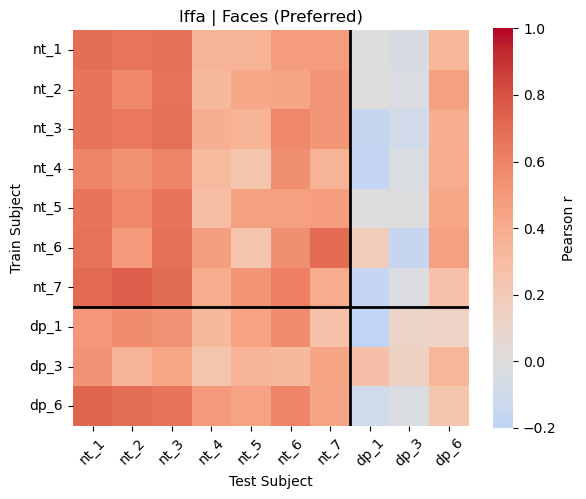

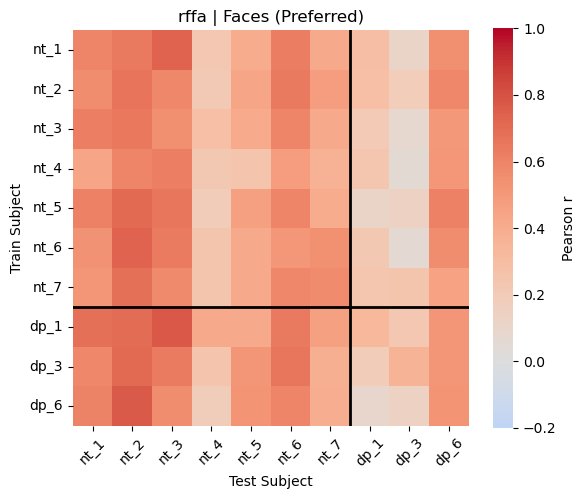

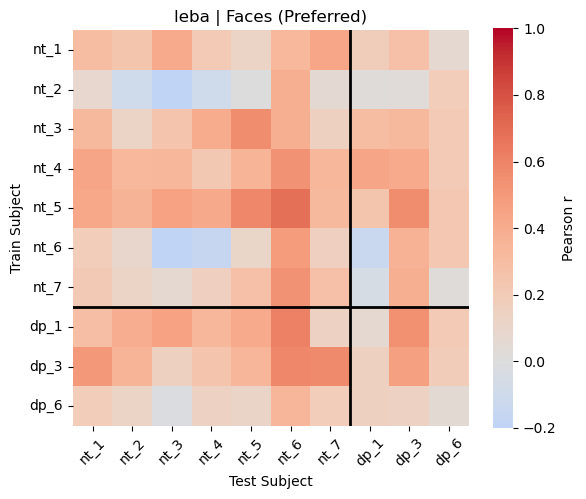

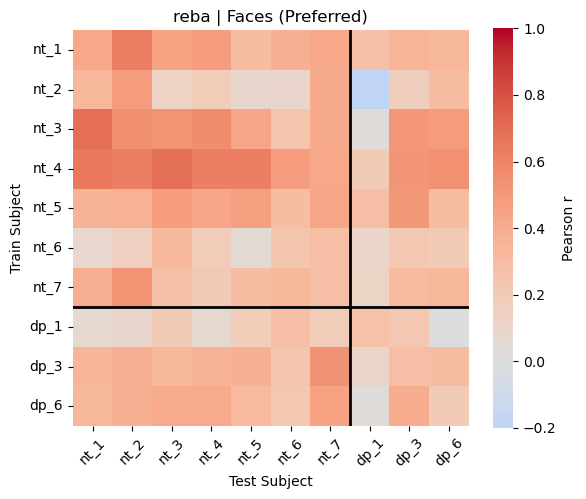

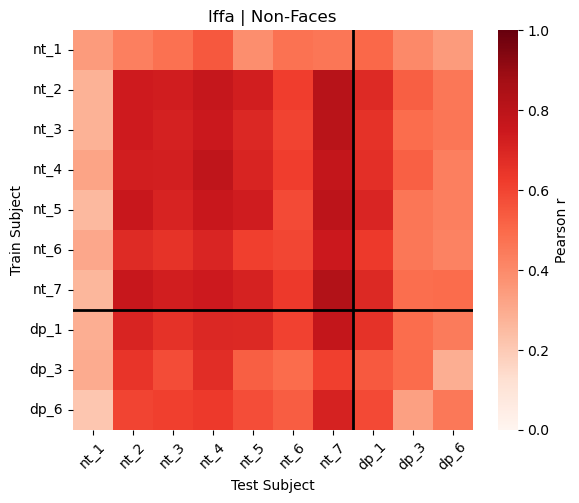

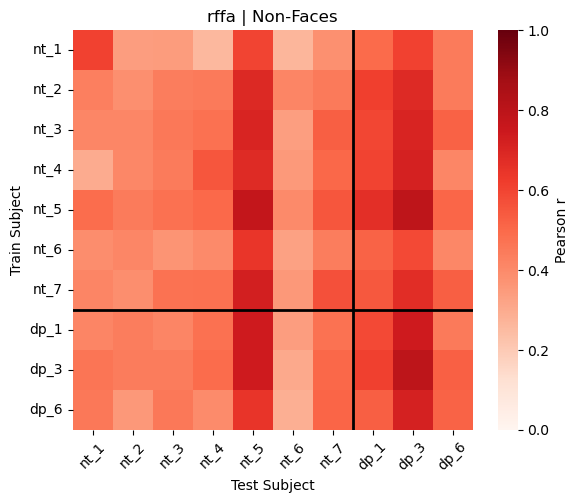

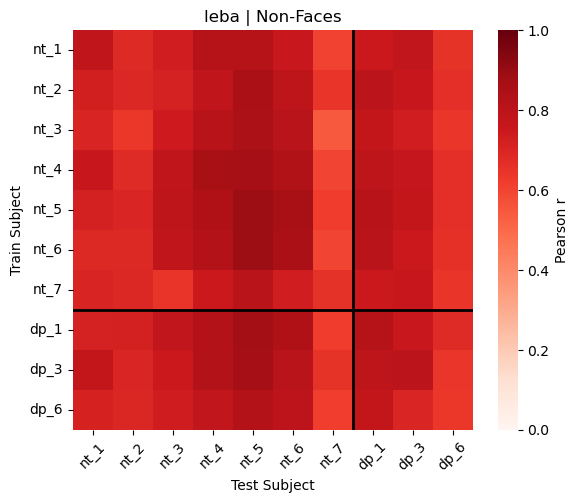

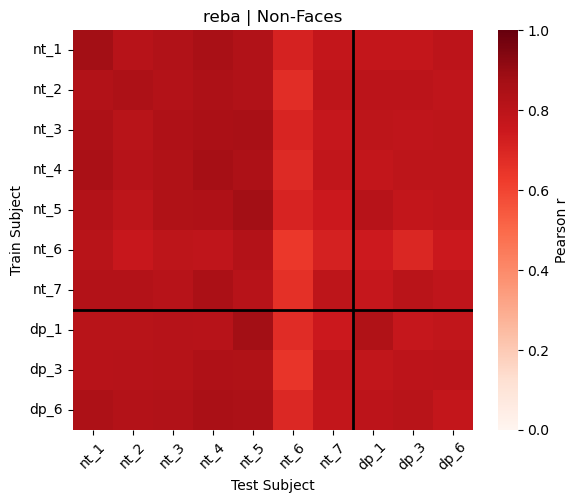

In [ ]:
# -------------------------------
# LOAD DATA
# -------------------------------
results_df_name = 'ccn_stimuli_responses_acrossgroup.csv'
results_df_path = f'{RESULTS_DIR}/{results_df_name}'
results_csv = pd.read_csv(results_df_path)

# -------------------------------
# CREATE CLEAN SUBJECT IDS
# -------------------------------
results_csv['train_subject_type'] = results_csv['train_subject_type'].astype(str).str.strip().str.lower()
results_csv['test_subject_type'] = results_csv['test_subject_type'].astype(str).str.strip().str.lower()

results_csv['train_subject'] = pd.to_numeric(results_csv['train_subject'], errors='coerce').astype('Int64')
results_csv['test_subject'] = pd.to_numeric(results_csv['test_subject'], errors='coerce').astype('Int64')

results_csv['train_id'] = results_csv['train_subject_type'] + '_' + results_csv['train_subject'].astype(str)
results_csv['test_id'] = results_csv['test_subject_type'] + '_' + results_csv['test_subject'].astype(str)

# -------------------------------
# DEFINE SUBJECT ORDER
# -------------------------------
subject_order = [
    'nt_1','nt_2','nt_3','nt_4','nt_5','nt_6','nt_7',
    'dp_1','dp_3','dp_6',
]

# Average across hemispheres after computing hemisphere-specific correlations
froi_pairs = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba'],
}

# -------------------------------
# BUILD MATRIX FUNCTION
# -------------------------------
def build_matrix(df, subject_order):

    n = len(subject_order)
    mat = np.full((n, n), np.nan)

    for i, train_subj in enumerate(subject_order):
        for j, test_subj in enumerate(subject_order):

            df_pair = df[
                (df['train_id'] == train_subj) &
                (df['test_id'] == test_subj)
            ]

            if len(df_pair) < 2:  # need at least 2 points
                continue

            corr = np.corrcoef(
                df_pair['y_prediction'],
                df_pair['y_observed']
            )[0, 1]

            mat[i, j] = corr

    return mat

# -------------------------------
# BUILD MATRICES (HEMISPHERE AVG)
# -------------------------------
face_stim_corrs = {}
nonface_stim_corrs = {}

for froi_group, hemis in froi_pairs.items():

    face_mats = []
    nonface_mats = []

    for froi in hemis:
        df_sub = results_csv[results_csv['froi'] == froi].copy()

        df_faces = df_sub[df_sub['img_cat'] == 'faces']
        df_nonfaces = df_sub[df_sub['img_cat'] != 'faces']

        face_mats.append(build_matrix(df_faces, subject_order))
        nonface_mats.append(build_matrix(df_nonfaces, subject_order))

    face_stim_corrs[froi_group] = np.nanmean(np.stack(face_mats, axis=0), axis=0)
    nonface_stim_corrs[froi_group] = np.nanmean(np.stack(nonface_mats, axis=0), axis=0)

# -------------------------------
# PLOT: 2x2 GRID
# FFA row 1, EBA row 2
# Faces col 1, Non-Preferred col 2
# -------------------------------
froi_order = ['ffa', 'eba']
tick_positions = [3, 8]  # centers of NT (0..6) and DP (7..9)
tick_labels = ['NT', 'DP']
boundary = 7

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for r, froi_group in enumerate(froi_order):
    # Faces (Preferred)
    ax = axes[r, 0]
    sns.heatmap(
        face_stim_corrs[froi_group],
        cmap='coolwarm',
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary, color='black', linewidth=2)
    ax.axvline(boundary, color='black', linewidth=2)
    ax.set_title(f'{froi_group.upper()} | Faces (Preferred)')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

    # Non-faces (Non-Preferred)
    ax = axes[r, 1]
    sns.heatmap(
        nonface_stim_corrs[froi_group],
        cmap='Reds',
        vmin=0,
        vmax=1,
        square=True,
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary, color='black', linewidth=2)
    ax.axvline(boundary, color='black', linewidth=2)
    ax.set_title(f'{froi_group.upper()} | Non-Preferred')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

plt.show()

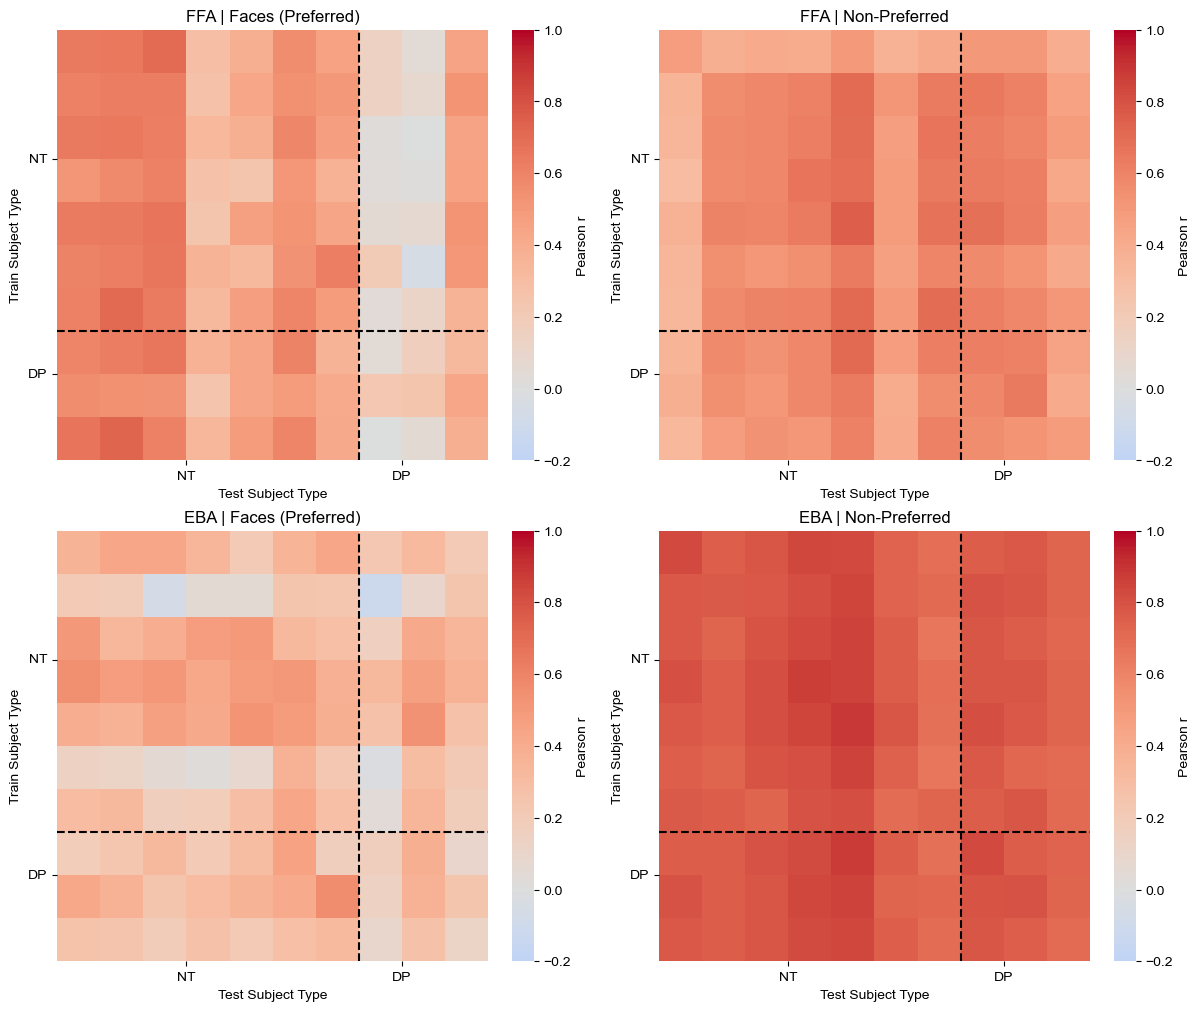

In [12]:
savefig = True
plot_dir = f'{RESULTS_DIR}/plots'

# -------------------------------
# LOAD DATA
# -------------------------------
results_df_name = 'ccn_stimuli_responses_acrossgroup.csv'
results_df_path = f'{RESULTS_DIR}/{results_df_name}'
results_csv = pd.read_csv(results_df_path)

# -------------------------------
# CREATE CLEAN SUBJECT IDS
# -------------------------------
results_csv['train_subject_type'] = results_csv['train_subject_type'].astype(str).str.strip().str.lower()
results_csv['test_subject_type'] = results_csv['test_subject_type'].astype(str).str.strip().str.lower()

results_csv['train_subject'] = pd.to_numeric(results_csv['train_subject'], errors='coerce').astype('Int64')
results_csv['test_subject'] = pd.to_numeric(results_csv['test_subject'], errors='coerce').astype('Int64')

results_csv['train_id'] = results_csv['train_subject_type'] + '_' + results_csv['train_subject'].astype(str)
results_csv['test_id'] = results_csv['test_subject_type'] + '_' + results_csv['test_subject'].astype(str)

# -------------------------------
# DEFINE SUBJECT ORDER
# -------------------------------
subject_order = [
    'nt_1','nt_2','nt_3','nt_4','nt_5','nt_6','nt_7',
    'dp_1','dp_3','dp_6',
]

# Average across hemispheres after computing hemisphere-specific correlations
froi_pairs = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba'],
}

# -------------------------------
# BUILD MATRIX FUNCTION
# -------------------------------
def build_matrix(df, subject_order):

    n = len(subject_order)
    mat = np.full((n, n), np.nan)

    for i, train_subj in enumerate(subject_order):
        for j, test_subj in enumerate(subject_order):

            df_pair = df[
                (df['train_id'] == train_subj) &
                (df['test_id'] == test_subj)
            ]

            if len(df_pair) < 2:  # need at least 2 points
                continue

            corr = np.corrcoef(
                df_pair['y_prediction'],
                df_pair['y_observed']
            )[0, 1]

            mat[i, j] = corr

    return mat

# -------------------------------
# BUILD MATRICES (HEMISPHERE AVG)
# -------------------------------
face_stim_corrs = {}
nonface_stim_corrs = {}

for froi_group, hemis in froi_pairs.items():

    face_mats = []
    nonface_mats = []

    for froi in hemis:
        df_sub = results_csv[results_csv['froi'] == froi].copy()

        df_faces = df_sub[df_sub['img_cat'] == 'faces']
        df_nonfaces = df_sub[df_sub['img_cat'] != 'faces']

        face_mats.append(build_matrix(df_faces, subject_order))
        nonface_mats.append(build_matrix(df_nonfaces, subject_order))

    face_stim_corrs[froi_group] = np.nanmean(np.stack(face_mats, axis=0), axis=0)
    nonface_stim_corrs[froi_group] = np.nanmean(np.stack(nonface_mats, axis=0), axis=0)

# -------------------------------
# PLOT: 2x2 GRID
# FFA row 1, EBA row 2
# Faces col 1, Non-Preferred col 2
# -------------------------------
froi_order = ['ffa', 'eba']
tick_positions = [3, 8]  # centers of NT (0..6) and DP (7..9)
tick_labels = ['NT', 'DP']
boundary = 7

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for r, froi_group in enumerate(froi_order):
    # Faces (Preferred)
    ax = axes[r, 0]
    sns.heatmap(
        face_stim_corrs[froi_group],
        cmap='coolwarm',
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.set_title(f'{froi_group.upper()} | Faces (Preferred)')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

    # Non-faces (Non-Preferred)
    ax = axes[r, 1]
    sns.heatmap(
        nonface_stim_corrs[froi_group],
        cmap='coolwarm',
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.set_title(f'{froi_group.upper()} | Non-Preferred')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)

plt.show()

In [ ]:
savefig = False
plot_dir = f'{RESULTS_DIR}/plots'

# -------------------------------
# LOAD DATA
# -------------------------------
results_df_name = 'ccn_stimuli_responses_acrossgroup.csv'
results_df_path = f'{RESULTS_DIR}/{results_df_name}'
results_csv = pd.read_csv(results_df_path)

# -------------------------------
# CREATE CLEAN SUBJECT IDS
# -------------------------------
results_csv['train_subject_type'] = results_csv['train_subject_type'].astype(str).str.strip().str.lower()
results_csv['test_subject_type'] = results_csv['test_subject_type'].astype(str).str.strip().str.lower()

results_csv['train_subject'] = pd.to_numeric(results_csv['train_subject'], errors='coerce').astype('Int64')
results_csv['test_subject'] = pd.to_numeric(results_csv['test_subject'], errors='coerce').astype('Int64')

results_csv['train_id'] = results_csv['train_subject_type'] + '_' + results_csv['train_subject'].astype(str)
results_csv['test_id'] = results_csv['test_subject_type'] + '_' + results_csv['test_subject'].astype(str)

# -------------------------------
# DEFINE SUBJECT ORDER
# -------------------------------
subject_order = [
    'nt_1','nt_2','nt_3','nt_4','nt_5','nt_6','nt_7',
    'dp_1','dp_3','dp_6',
]

# Average across hemispheres after computing hemisphere-specific correlations
froi_pairs = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba'],
}

# -------------------------------
# BUILD MATRIX FUNCTION
# -------------------------------
def build_matrix(df, subject_order):

    n = len(subject_order)
    mat = np.full((n, n), np.nan)

    for i, train_subj in enumerate(subject_order):
        for j, test_subj in enumerate(subject_order):

            df_pair = df[
                (df['train_id'] == train_subj) &
                (df['test_id'] == test_subj)
            ]

            if len(df_pair) < 2:  # need at least 2 points
                continue

            corr = np.corrcoef(
                df_pair['y_prediction'],
                df_pair['y_observed']
            )[0, 1]

            mat[i, j] = corr

    return mat

def append_mean_row_col_with_gap(mat):
    """Append a spacer row/col before mean row/col for visual separation."""
    n, m = mat.shape
    out = np.full((n + 2, m + 2), np.nan)

    # Original matrix
    out[:n, :m] = mat

    # Means
    row_valid = np.sum(~np.isnan(mat), axis=1)
    col_valid = np.sum(~np.isnan(mat), axis=0)

    out[:n, m + 1] = np.where(row_valid > 0, np.nansum(mat, axis=1) / row_valid, np.nan)
    out[n + 1, :m] = np.where(col_valid > 0, np.nansum(mat, axis=0) / col_valid, np.nan)

    total_valid = np.sum(~np.isnan(mat))
    out[n + 1, m + 1] = np.nansum(mat) / total_valid if total_valid > 0 else np.nan

    return out

# -------------------------------
# BUILD MATRICES (HEMISPHERE AVG)
# -------------------------------
face_stim_corrs = {}
nonface_stim_corrs = {}

for froi_group, hemis in froi_pairs.items():

    face_mats = []
    nonface_mats = []

    for froi in hemis:
        df_sub = results_csv[results_csv['froi'] == froi].copy()

        df_faces = df_sub[df_sub['img_cat'] == 'faces']
        df_nonfaces = df_sub[df_sub['img_cat'] != 'faces']

        face_mats.append(build_matrix(df_faces, subject_order))
        nonface_mats.append(build_matrix(df_nonfaces, subject_order))

    face_stim_corrs[froi_group] = np.nanmean(np.stack(face_mats, axis=0), axis=0)
    nonface_stim_corrs[froi_group] = np.nanmean(np.stack(nonface_mats, axis=0), axis=0)

# -------------------------------
# PLOT: 2x2 GRID + MEAN ROW/COL
# FFA row 1, EBA row 2
# Faces col 1, Non-Preferred col 2
# -------------------------------
froi_order = ['ffa', 'eba']
tick_positions = [3.5, 8.5, 11.5]  # NT center, DP center, Mean cell
tick_labels = ['NT', 'DP', 'Mean']
boundary_main = 7
spacer_col = 10
spacer_row = 10
cmap = plt.cm.get_cmap('coolwarm').copy()
cmap.set_bad('#f2f2f2')  # make spacer clearly visible

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11),
    gridspec_kw={'wspace': 0.28, 'hspace': 0.34}
 )

for r, froi_group in enumerate(froi_order):
    # Faces (Preferred)
    ax = axes[r, 0]
    mat_plot = append_mean_row_col_with_gap(face_stim_corrs[froi_group])
    sns.heatmap(
        mat_plot,
        cmap=cmap,
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        linewidths=0.5,
        linecolor='white',
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    # ax.axhline(spacer_row, color='black', linewidth=1.2)
    # ax.axhline(spacer_row + 1, color='black', linewidth=1.2)
    # ax.axvline(spacer_col, color='black', linewidth=1.2)
    # ax.axvline(spacer_col + 1, color='black', linewidth=1.2)
    ax.set_title(f'{froi_group.upper()} | Faces (Preferred)')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

    # Non-faces (Non-Preferred)
    ax = axes[r, 1]
    mat_plot = append_mean_row_col_with_gap(nonface_stim_corrs[froi_group])
    sns.heatmap(
        mat_plot,
        cmap=cmap,
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        linewidths=0.5,
        linecolor='white',
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    # ax.axhline(spacer_row, color='black', linewidth=1.2)
    # ax.axhline(spacer_row + 1, color='black', linewidth=1.2)
    # ax.axvline(spacer_col, color='black', linewidth=1.2)
    # ax.axvline(spacer_col + 1, color='black', linewidth=1.2)
    ax.set_title(f'{froi_group.upper()} | Non-Preferred')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)

plt.show()

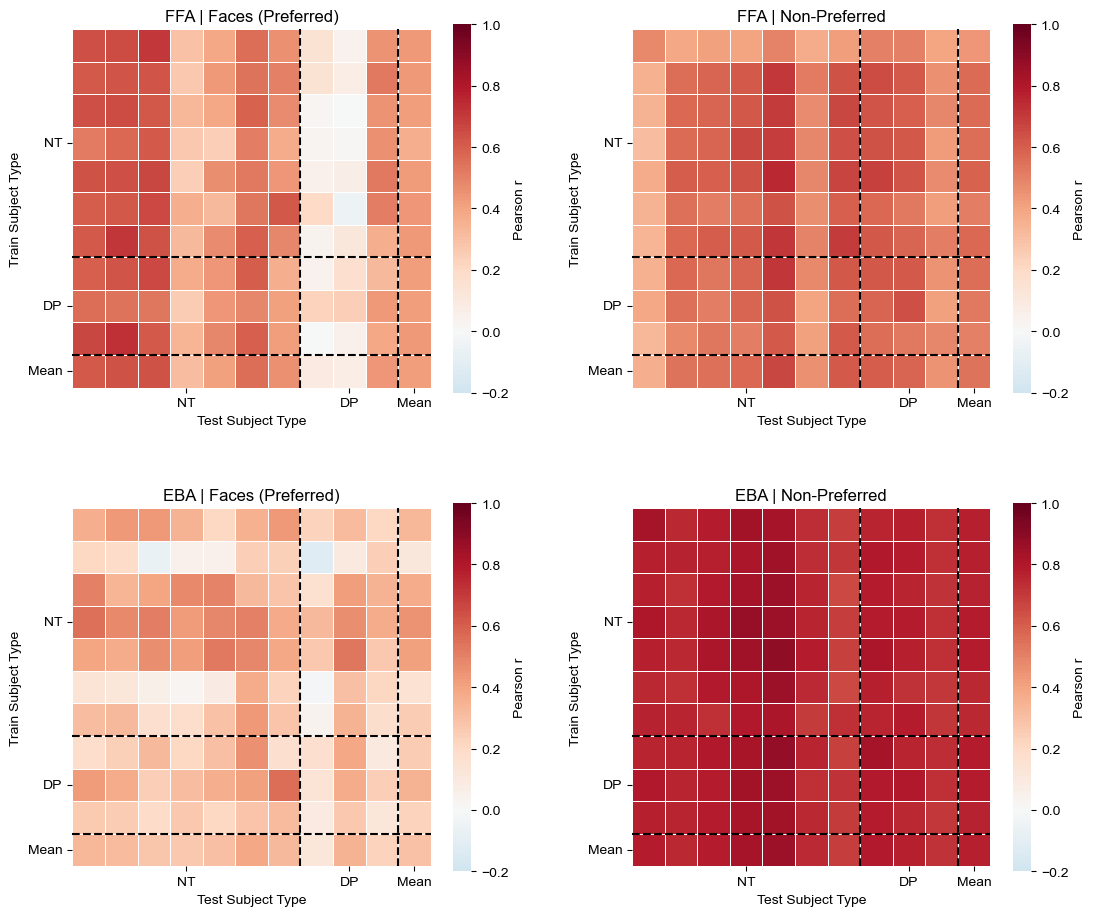

In [35]:
savefig = False
plot_dir = f'{RESULTS_DIR}/plots'

# -------------------------------
# LOAD DATA
# -------------------------------
results_df_name = 'ccn_stimuli_responses_acrossgroup.csv'
results_df_path = f'{RESULTS_DIR}/{results_df_name}'
results_csv = pd.read_csv(results_df_path)

# -------------------------------
# CREATE CLEAN SUBJECT IDS
# -------------------------------
results_csv['train_subject_type'] = results_csv['train_subject_type'].astype(str).str.strip().str.lower()
results_csv['test_subject_type'] = results_csv['test_subject_type'].astype(str).str.strip().str.lower()

results_csv['train_subject'] = pd.to_numeric(results_csv['train_subject'], errors='coerce').astype('Int64')
results_csv['test_subject'] = pd.to_numeric(results_csv['test_subject'], errors='coerce').astype('Int64')

results_csv['train_id'] = results_csv['train_subject_type'] + '_' + results_csv['train_subject'].astype(str)
results_csv['test_id'] = results_csv['test_subject_type'] + '_' + results_csv['test_subject'].astype(str)

# -------------------------------
# DEFINE SUBJECT ORDER
# -------------------------------
subject_order = [
    'nt_1','nt_2','nt_3','nt_4','nt_5','nt_6','nt_7',
    'dp_1','dp_3','dp_6',
]

# Average across hemispheres after computing hemisphere-specific correlations
froi_pairs = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba'],
}

# -------------------------------
# BUILD MATRIX FUNCTION
# -------------------------------
def build_matrix(df, subject_order):

    n = len(subject_order)
    mat = np.full((n, n), np.nan)

    for i, train_subj in enumerate(subject_order):
        for j, test_subj in enumerate(subject_order):

            df_pair = df[
                (df['train_id'] == train_subj) &
                (df['test_id'] == test_subj)
            ]

            if len(df_pair) < 2:  # need at least 2 points
                continue

            corr = np.corrcoef(
                df_pair['y_prediction'],
                df_pair['y_observed']
            )[0, 1]

            mat[i, j] = corr

    return mat

def append_mean_row_col(mat):
    """Append right-most column = row mean, bottom row = column mean."""
    n, m = mat.shape
    out = np.full((n + 1, m + 1), np.nan)
    out[:n, :m] = mat

    row_valid = np.sum(~np.isnan(mat), axis=1)
    col_valid = np.sum(~np.isnan(mat), axis=0)

    out[:n, m] = np.where(row_valid > 0, np.nansum(mat, axis=1) / row_valid, np.nan)
    out[n, :m] = np.where(col_valid > 0, np.nansum(mat, axis=0) / col_valid, np.nan)

    total_valid = np.sum(~np.isnan(mat))
    out[n, m] = np.nansum(mat) / total_valid if total_valid > 0 else np.nan

    return out

# -------------------------------
# BUILD MATRICES (HEMISPHERE AVG)
# -------------------------------
face_stim_corrs = {}
nonface_stim_corrs = {}

for froi_group, hemis in froi_pairs.items():

    face_mats = []
    nonface_mats = []

    for froi in hemis:
        df_sub = results_csv[results_csv['froi'] == froi].copy()

        df_faces = df_sub[df_sub['img_cat'] == 'faces']
        df_nonfaces = df_sub[df_sub['img_cat'] != 'faces']

        face_mats.append(build_matrix(df_faces, subject_order))
        nonface_mats.append(build_matrix(df_nonfaces, subject_order))

    face_stim_corrs[froi_group] = np.nanmean(np.stack(face_mats, axis=0), axis=0)
    nonface_stim_corrs[froi_group] = np.nanmean(np.stack(nonface_mats, axis=0), axis=0)

# -------------------------------
# PLOT: 2x2 GRID + MEAN ROW/COL
# FFA row 1, EBA row 2
# Faces col 1, Non-Preferred col 2
# -------------------------------
froi_order = ['ffa', 'eba']
tick_positions = [3.5, 8.5, 10.5]  # NT center, DP center, Mean cell
tick_labels = ['NT', 'DP', 'Mean']
boundary_main = 7
boundary_mean = 10
cmap = 'RdBu_r'

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11),
    gridspec_kw={'wspace': 0.25, 'hspace': 0.30}
 )

for r, froi_group in enumerate(froi_order):
    # Faces (Preferred)
    ax = axes[r, 0]
    mat_plot = append_mean_row_col(face_stim_corrs[froi_group])
    sns.heatmap(
        mat_plot,
        cmap=cmap,
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        linewidths=0.6,
        linecolor='white',
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    ax.axhline(boundary_mean, linestyle='--', color='black', linewidth=1.5) #, alpha=0.5)
    ax.axvline(boundary_mean, linestyle='--', color='black', linewidth=1.5) #, alpha=0.5)
    ax.set_title(f'{froi_group.upper()} | Faces (Preferred)')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

    # Non-faces (Non-Preferred)
    ax = axes[r, 1]
    mat_plot = append_mean_row_col(nonface_stim_corrs[froi_group])
    sns.heatmap(
        mat_plot,
        cmap=cmap,
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        linewidths=0.6,
        linecolor='white',
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary_main, linestyle='--', color='black', linewidth=1.5)
    ax.axhline(boundary_mean, linestyle='--', color='black', linewidth=1.5) #, alpha=0.5)
    ax.axvline(boundary_mean, linestyle='--', color='black', linewidth=1.5) #, alpha=0.5)
    ax.set_title(f'{froi_group.upper()} | Non-Preferred')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)

plt.show()

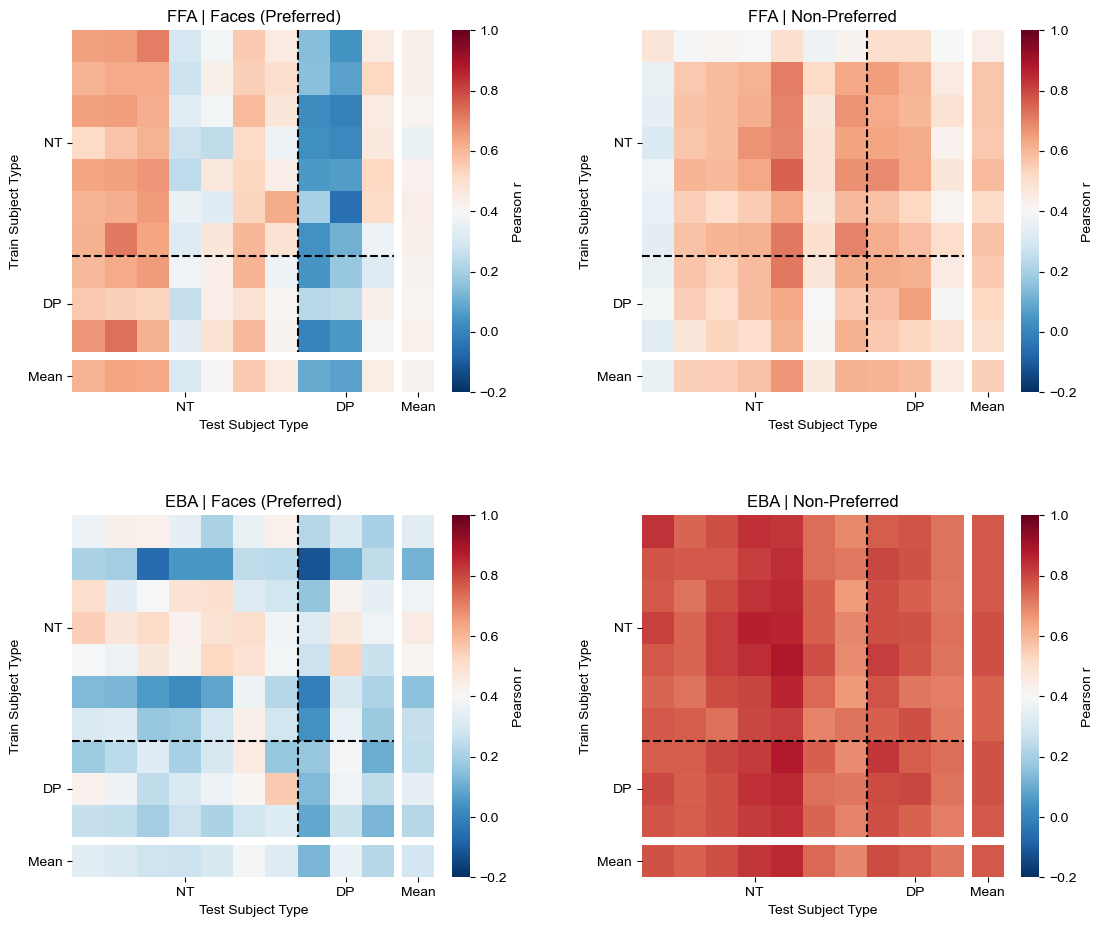

In [29]:
savefig = False
plot_dir = f'{RESULTS_DIR}/plots'

# -------------------------------
# LOAD DATA
# -------------------------------
results_df_name = 'ccn_stimuli_responses_acrossgroup.csv'
results_df_path = f'{RESULTS_DIR}/{results_df_name}'
results_csv = pd.read_csv(results_df_path)

# -------------------------------
# CREATE CLEAN SUBJECT IDS
# -------------------------------
results_csv['train_subject_type'] = results_csv['train_subject_type'].astype(str).str.strip().str.lower()
results_csv['test_subject_type'] = results_csv['test_subject_type'].astype(str).str.strip().str.lower()

results_csv['train_subject'] = pd.to_numeric(results_csv['train_subject'], errors='coerce').astype('Int64')
results_csv['test_subject'] = pd.to_numeric(results_csv['test_subject'], errors='coerce').astype('Int64')

results_csv['train_id'] = results_csv['train_subject_type'] + '_' + results_csv['train_subject'].astype(str)
results_csv['test_id'] = results_csv['test_subject_type'] + '_' + results_csv['test_subject'].astype(str)

# -------------------------------
# DEFINE SUBJECT ORDER
# -------------------------------
subject_order = [
    'nt_1','nt_2','nt_3','nt_4','nt_5','nt_6','nt_7',
    'dp_1','dp_3','dp_6',
]

# Average across hemispheres after computing hemisphere-specific correlations
froi_pairs = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba'],
}

# -------------------------------
# BUILD MATRIX FUNCTION
# -------------------------------
def build_matrix(df, subject_order):

    n = len(subject_order)
    mat = np.full((n, n), np.nan)

    for i, train_subj in enumerate(subject_order):
        for j, test_subj in enumerate(subject_order):

            df_pair = df[
                (df['train_id'] == train_subj) &
                (df['test_id'] == test_subj)
            ]

            if len(df_pair) < 2:  # need at least 2 points
                continue

            corr = np.corrcoef(
                df_pair['y_prediction'],
                df_pair['y_observed']
            )[0, 1]

            mat[i, j] = corr

    return mat

def append_mean_row_col_with_gap(mat):
    """Append spacer row/col before mean row/col for visual separation."""
    n, m = mat.shape
    out = np.full((n + 2, m + 2), np.nan)

    # Original matrix
    out[:n, :m] = mat

    # Means
    row_valid = np.sum(~np.isnan(mat), axis=1)
    col_valid = np.sum(~np.isnan(mat), axis=0)

    out[:n, m + 1] = np.where(row_valid > 0, np.nansum(mat, axis=1) / row_valid, np.nan)
    out[n + 1, :m] = np.where(col_valid > 0, np.nansum(mat, axis=0) / col_valid, np.nan)

    total_valid = np.sum(~np.isnan(mat))
    out[n + 1, m + 1] = np.nansum(mat) / total_valid if total_valid > 0 else np.nan

    # Keep spacer row/col as NaN so they render white
    return out

def draw_heatmap_with_variable_spacer(ax, mat_plot, title, vmin=-0.2, vmax=1, cmap_name='RdBu_r'):
    """Draw heatmap with thin spacer row/column and white spacer cells."""
    from matplotlib.colors import Normalize

    nrows, ncols = mat_plot.shape  # expected 12x12 for 10x10 + spacer + mean

    # Thin spacer sizes
    row_heights = [1.0] * nrows
    col_widths = [1.0] * ncols
    row_heights[10] = 0.25
    col_widths[10] = 0.25

    y_edges = np.concatenate([[0], np.cumsum(row_heights)])
    x_edges = np.concatenate([[0], np.cumsum(col_widths)])

    # Use the native RdBu_r endpoints directly (true blue min, true red max).
    cmap = plt.colormaps[cmap_name].copy()
    cmap.set_bad('#ffffff')

    norm = Normalize(vmin=vmin, vmax=vmax)
    mesh = ax.pcolormesh(
        x_edges,
        y_edges,
        np.ma.masked_invalid(mat_plot),
        cmap=cmap,
        norm=norm,
        shading='flat'
    )
    ax.invert_yaxis()
    ax.set_aspect('equal')
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Group boundaries + spacer boundaries
    # Draw NT/DP boundary only across the data block (exclude spacer + mean row/col)
    ax.hlines(
        y_edges[7],
        xmin=x_edges[0],
        xmax=x_edges[10],
        linestyles='--',
        colors='black',
        linewidth=1.5
    )
    ax.vlines(
        x_edges[7],
        ymin=y_edges[0],
        ymax=y_edges[10],
        linestyles='--',
        colors='black',
        linewidth=1.5
    )

    # Tick positions at group centers
    x_tick_positions = [
        (x_edges[0] + x_edges[7]) / 2,
        (x_edges[7] + x_edges[10]) / 2,
        (x_edges[11] + x_edges[12]) / 2,
    ]
    y_tick_positions = [
        (y_edges[0] + y_edges[7]) / 2,
        (y_edges[7] + y_edges[10]) / 2,
        (y_edges[11] + y_edges[12]) / 2,
    ]

    ax.set_xticks(x_tick_positions)
    ax.set_yticks(y_tick_positions)
    ax.set_xticklabels(['NT', 'DP', 'Mean'], rotation=0)
    ax.set_yticklabels(['NT', 'DP', 'Mean'], rotation=0)
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_title(title)

    return mesh

# -------------------------------
# BUILD MATRICES (HEMISPHERE AVG)
# -------------------------------
face_stim_corrs = {}
nonface_stim_corrs = {}

for froi_group, hemis in froi_pairs.items():

    face_mats = []
    nonface_mats = []

    for froi in hemis:
        df_sub = results_csv[results_csv['froi'] == froi].copy()

        df_faces = df_sub[df_sub['img_cat'] == 'faces']
        df_nonfaces = df_sub[df_sub['img_cat'] != 'faces']

        face_mats.append(build_matrix(df_faces, subject_order))
        nonface_mats.append(build_matrix(df_nonfaces, subject_order))

    face_stim_corrs[froi_group] = np.nanmean(np.stack(face_mats, axis=0), axis=0)
    nonface_stim_corrs[froi_group] = np.nanmean(np.stack(nonface_mats, axis=0), axis=0)

# -------------------------------
# PLOT: 2x2 GRID + MEAN ROW/COL
# FFA row 1, EBA row 2
# Faces col 1, Non-Preferred col 2
# -------------------------------
froi_order = ['ffa', 'eba']

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11),
    gridspec_kw={'wspace': 0.30, 'hspace': 0.34}
 )

for r, froi_group in enumerate(froi_order):
    # Faces (Preferred)
    ax = axes[r, 0]
    mat_plot = append_mean_row_col_with_gap(face_stim_corrs[froi_group])
    mesh = draw_heatmap_with_variable_spacer(
        ax,
        mat_plot,
        f'{froi_group.upper()} | Faces (Preferred)',
        vmin=-0.2,
        vmax=1,
        cmap_name='RdBu_r'
    )
    cbar = fig.colorbar(mesh, ax=ax, label='Pearson r', fraction=0.046, pad=0.04)
    cbar.outline.set_visible(False)
    for spine in cbar.ax.spines.values():
        spine.set_visible(False)

    # Non-faces (Non-Preferred)
    ax = axes[r, 1]
    mat_plot = append_mean_row_col_with_gap(nonface_stim_corrs[froi_group])
    mesh = draw_heatmap_with_variable_spacer(
        ax,
        mat_plot,
        f'{froi_group.upper()} | Non-Preferred',
        vmin=-0.2,
        vmax=1,
        cmap_name='RdBu_r'
    )
    cbar = fig.colorbar(mesh, ax=ax, label='Pearson r', fraction=0.046, pad=0.04)
    cbar.outline.set_visible(False)
    for spine in cbar.ax.spines.values():
        spine.set_visible(False)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)

plt.show()

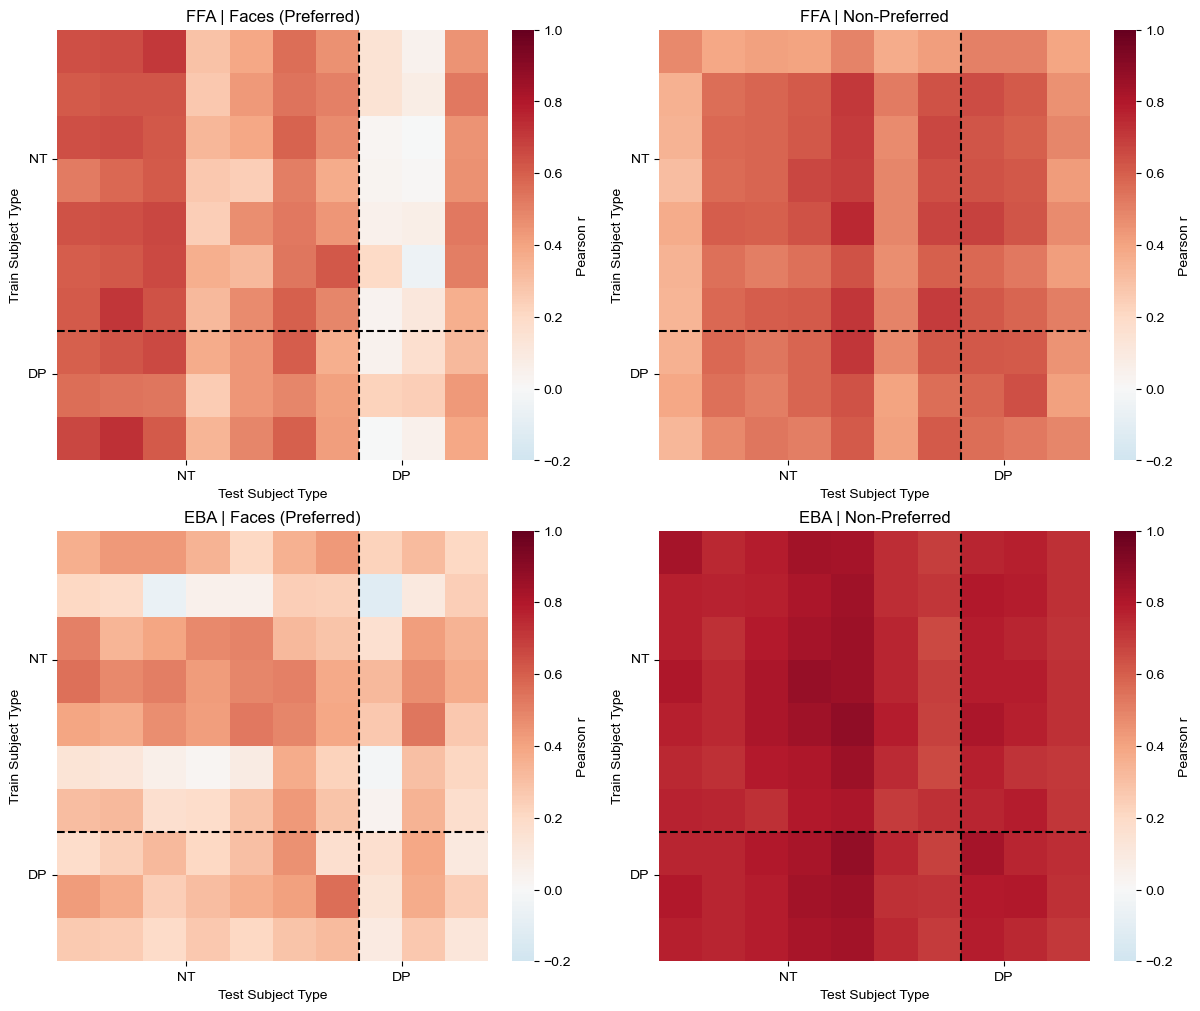

In [37]:
savefig = True
plot_dir = f'{RESULTS_DIR}/plots'

# -------------------------------
# LOAD DATA
# -------------------------------
results_df_name = 'ccn_stimuli_responses_acrossgroup.csv'
results_df_path = f'{RESULTS_DIR}/{results_df_name}'
results_csv = pd.read_csv(results_df_path)

# -------------------------------
# CREATE CLEAN SUBJECT IDS
# -------------------------------
results_csv['train_subject_type'] = results_csv['train_subject_type'].astype(str).str.strip().str.lower()
results_csv['test_subject_type'] = results_csv['test_subject_type'].astype(str).str.strip().str.lower()

results_csv['train_subject'] = pd.to_numeric(results_csv['train_subject'], errors='coerce').astype('Int64')
results_csv['test_subject'] = pd.to_numeric(results_csv['test_subject'], errors='coerce').astype('Int64')

results_csv['train_id'] = results_csv['train_subject_type'] + '_' + results_csv['train_subject'].astype(str)
results_csv['test_id'] = results_csv['test_subject_type'] + '_' + results_csv['test_subject'].astype(str)

# -------------------------------
# DEFINE SUBJECT ORDER
# -------------------------------
subject_order = [
    'nt_1','nt_2','nt_3','nt_4','nt_5','nt_6','nt_7',
    'dp_1','dp_3','dp_6',
]

# Average across hemispheres after computing hemisphere-specific correlations
froi_pairs = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba'],
}

# -------------------------------
# BUILD MATRIX FUNCTION
# -------------------------------
def build_matrix(df, subject_order):

    n = len(subject_order)
    mat = np.full((n, n), np.nan)

    for i, train_subj in enumerate(subject_order):
        for j, test_subj in enumerate(subject_order):

            df_pair = df[
                (df['train_id'] == train_subj) &
                (df['test_id'] == test_subj)
            ]

            if len(df_pair) < 2:  # need at least 2 points
                continue

            corr = np.corrcoef(
                df_pair['y_prediction'],
                df_pair['y_observed']
            )[0, 1]

            mat[i, j] = corr

    return mat

# -------------------------------
# BUILD MATRICES (HEMISPHERE AVG)
# -------------------------------
face_stim_corrs = {}
nonface_stim_corrs = {}

for froi_group, hemis in froi_pairs.items():

    face_mats = []
    nonface_mats = []

    for froi in hemis:
        df_sub = results_csv[results_csv['froi'] == froi].copy()

        df_faces = df_sub[df_sub['img_cat'] == 'faces']
        df_nonfaces = df_sub[df_sub['img_cat'] != 'faces']

        face_mats.append(build_matrix(df_faces, subject_order))
        nonface_mats.append(build_matrix(df_nonfaces, subject_order))

    face_stim_corrs[froi_group] = np.nanmean(np.stack(face_mats, axis=0), axis=0)
    nonface_stim_corrs[froi_group] = np.nanmean(np.stack(nonface_mats, axis=0), axis=0)

# -------------------------------
# PLOT: 2x2 GRID
# FFA row 1, EBA row 2
# Faces col 1, Non-Preferred col 2
# -------------------------------
froi_order = ['ffa', 'eba']
tick_positions = [3, 8]  # centers of NT (0..6) and DP (7..9)
tick_labels = ['NT', 'DP']
boundary = 7
cmap = 'RdBu_r'

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for r, froi_group in enumerate(froi_order):
    # Faces (Preferred)
    ax = axes[r, 0]
    sns.heatmap(
        face_stim_corrs[froi_group],
        cmap=cmap,
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.set_title(f'{froi_group.upper()} | Faces (Preferred)')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

    # Non-faces (Non-Preferred)
    ax = axes[r, 1]
    sns.heatmap(
        nonface_stim_corrs[froi_group],
        cmap=cmap,
        vmin=-0.2,
        center=0,
        vmax=1,
        square=True,
        cbar_kws={'label': 'Pearson r'},
        ax=ax
    )
    ax.axhline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.axvline(boundary, linestyle='--', color='black', linewidth=1.5)
    ax.set_title(f'{froi_group.upper()} | Non-Preferred')
    ax.set_xlabel('Test Subject Type')
    ax.set_ylabel('Train Subject Type')
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)

plt.show()